 # Mach-zender interferiometer characterization and simulation

In [250]:
import numpy as np
import matplotlib.pyplot as plt

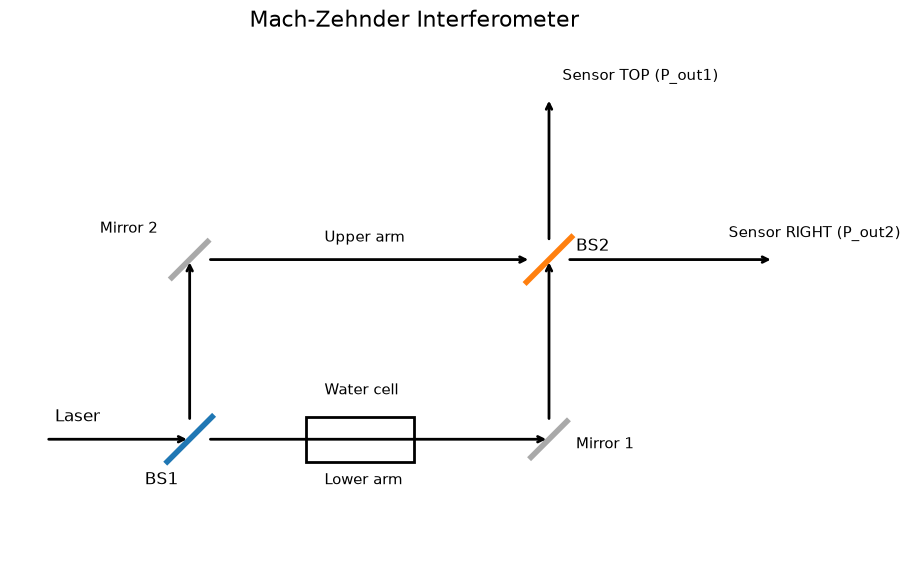

In [251]:
# This is a drawing that I asked Chatgpt to do
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(12, 7))

# ---------------------------------
# 1. Laser input
# ---------------------------------

ax.annotate(
    "",
    xy=(2, 3),
    xytext=(0.4, 3),
    arrowprops=dict(arrowstyle="->", lw=2)
)

ax.text(0.5, 3.2, "Laser", fontsize=12)


# ---------------------------------
# 2. Beam splitter 1
# ---------------------------------

BS1 = (2, 3)

ax.plot(
    [BS1[0]-0.25, BS1[0]+0.25],
    [BS1[1]-0.25, BS1[1]+0.25],
    linewidth=4
)

ax.text(1.5, 2.5, "BS1", fontsize=12)


# ---------------------------------
# 3. Lower arm
# ---------------------------------

# BS1 -> Mirror 1
ax.annotate(
    "",
    xy=(6, 3),
    xytext=(2.2, 3),
    arrowprops=dict(arrowstyle="->", lw=2)
)

# Mirror 1 -> BS2
ax.annotate(
    "",
    xy=(6, 5),
    xytext=(6, 3.2),
    arrowprops=dict(arrowstyle="->", lw=2)
)


# ---------------------------------
# 4. Upper arm
# ---------------------------------

# BS1 -> Mirror 2
ax.annotate(
    "",
    xy=(2, 5),
    xytext=(2, 3.2),
    arrowprops=dict(arrowstyle="->", lw=2)
)

# Mirror 2 -> BS2
ax.annotate(
    "",
    xy=(5.8, 5),
    xytext=(2.2, 5),
    arrowprops=dict(arrowstyle="->", lw=2)
)


# ---------------------------------
# 5. Mirrors
# ---------------------------------

# Mirror 1
ax.plot([5.8, 6.2], [2.8, 3.2], linewidth=4, color="darkgrey")
ax.text(6.3, 2.9, "Mirror 1", fontsize=11)

# Mirror 2
ax.plot([1.8, 2.2], [4.8, 5.2], linewidth=4, color="darkgrey")
ax.text(1.0, 5.3, "Mirror 2", fontsize=11)


# ---------------------------------
# 6. Water container
# ---------------------------------

water_cell = Rectangle(
    (3.3, 2.75),
    1.2,
    0.5,
    fill=False,
    linewidth=2
)

ax.add_patch(water_cell)

ax.text(3.5, 3.5, "Water cell", fontsize=11)


# ---------------------------------
# 7. Beam splitter 2
# ---------------------------------

BS2 = (6, 5)

ax.plot(
    [BS2[0]-0.25, BS2[0]+0.25],
    [BS2[1]-0.25, BS2[1]+0.25],
    linewidth=4
)

ax.text(6.3, 5.1, "BS2", fontsize=12)


# ---------------------------------
# 8. Output beams
# ---------------------------------

# Output 1: TOP
ax.annotate(
    "",
    xy=(6, 6.8),
    xytext=(6, 5.2),
    arrowprops=dict(arrowstyle="->", lw=2)
)

ax.text(6.15, 7.0, "Sensor TOP (P_out1)", fontsize=11)

# Output 2: RIGHT
ax.annotate(
    "",
    xy=(8.5, 5),
    xytext=(6.2, 5),
    arrowprops=dict(arrowstyle="->", lw=2)
)

ax.text(8.0, 5.25, "Sensor RIGHT (P_out2)", fontsize=11)


# ---------------------------------
# 9. Labels and formatting
# ---------------------------------

ax.text(3.5, 2.5, "Lower arm", fontsize=11)
ax.text(3.5, 5.2, "Upper arm", fontsize=11)

ax.set_title("Mach-Zehnder Interferometer", fontsize=16)

ax.set_xlim(0, 9)
ax.set_ylim(1.5, 7.5)

ax.set_aspect("equal")
ax.axis("off")

plt.show()


## The characterization of the MZI is:
### $$E_{out}=B_2D_\phi B_1E_{in}$$
#### Where:
$B_2=B_1=\begin{pmatrix}\sqrt{T}&i\sqrt{R}\\i\sqrt{R}&\sqrt{T}\end{pmatrix}$

$D_\phi=\begin{pmatrix}e^{i\phi}&0\\0&1\end{pmatrix}$

$E_{in}=\begin{pmatrix}\sqrt{P_{in}}\\0\end{pmatrix}$

### Variables:

In [ ]:
P_in = 0.4e-3 # We set the power of the laser as 0.4 mW
R1 = 0.06 # We set the reflectivity of the first beam splitter
R2 = 0.06 # We set the reflectivity of the second beam splitter

#### We want to define this matrix as our ideal beam splitter
$$B=\begin{pmatrix}\sqrt{T}&i\sqrt{R}\\i\sqrt{R}&\sqrt{T}\end{pmatrix}$$

Where $R$ is the Reflectivity of the beam splitter and $T$ the Trasmitance

In [253]:
def beam_splitter_matrix(R):

    if not 0 <= R <= 1:
        raise ValueError("Reflectivity must be between 0 and 1")

    
    T = 1 - R # T is the trasmitance. An ideal beam splitter doesnt have any loses

   
    B = np.array([[np.sqrt(T), 1j * np.sqrt(R)], [1j * np.sqrt(R), np.sqrt(T)]], dtype=complex) # Beam splitter matrix

    return B


#### Now we define the full characterization
We want the result to be the power of light that will be measured by the photodiodes

In [254]:
def mzi_simulator(phi):

    
    E_in = np.array([np.sqrt(P_in), 0], dtype=complex) # We create the laser energy field vector

    
    B1 = beam_splitter_matrix(R1) 
    E_after_BS1 = B1 @ E_in # We apply the first beam splitter

    
    D = np.diag([np.exp(1j * phi), 1]) # We define the matrix that represents the phase change in each arm of the MZI before the final beam splitter. phi is the phase change that we want to add to the bottom arm
    E_after_arms = D @ E_after_BS1 # We apply the phase changes


    B2 = beam_splitter_matrix(R2) 
    E_out = B2 @ E_after_arms # We apply the second beam splitter

    # We extract the optical power at each output from the energy field vector
    P_top = np.abs(E_out[0])**2 # Top detector output
    P_right = np.abs(E_out[1])**2 # Right detector output

    return P_top, P_right

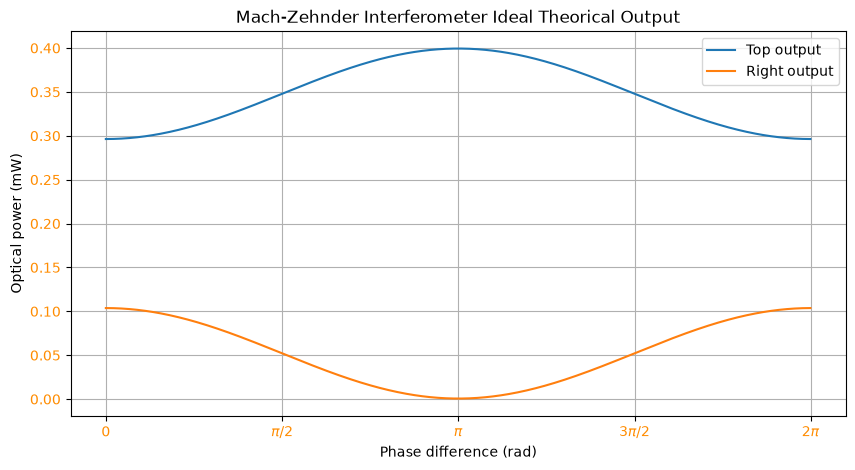

In [255]:
possible_phi = np.arange(0, 2*np.pi, 0.01) # We define all the possible values of phi

results = np.array([mzi_simulator(phi) for phi in possible_phi]) # We simulate the power output for each value of phi
P_top = results[:, 0] # We get the power of only the top sensor
P_right = results[:, 1] # We get the power of only the right sensor

plt.figure(figsize=(10, 5))
plt.plot(possible_phi, P_top * 1000, label="Top output") # We plot the top sensor output
plt.plot(possible_phi, P_right * 1000, label="Right output") # We plot the right sensor output
plt.title("Mach-Zehnder Interferometer Ideal Theorical Output")
plt.xlabel("Phase difference (rad)")
plt.ylabel("Optical power (mW)")
plt.yticks(np.arange(0, 0.45, 0.05), color="darkorange")       #The values of the y axis 
plt.xticks(np.arange(0, 2.5*np.pi, np.pi/2), ["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"], color="darkorange") # We choose apropiate values of the phase and their labels
plt.grid(True)
plt.legend()
plt.show()